# Módulo 5 — Transformações Box–Cox

## Seção 4 — Inversão de previsões, viés de retransformação e interpretação na escala original

**Estado editorial:** seção didática para revisão. **Pré-requisitos:** Módulo 5, Seções 1–3; esperança, variância, convexidade e fórmula de Taylor. **Programação:** NumPy, SciPy e Matplotlib; dados inteiramente sintéticos.

**Rastreabilidade.** O `PLANO_MODULOS_PRIORITARIOS.md` prevê distinguir média e mediana ao inverter Box–Cox; o `mapeamento-conteudos-series-temporais.md` registra cobertura parcial da correção de viés. O desenvolvimento matemático e os experimentos abaixo são **complementações didáticas originais**. A transformação de Box–Cox foi definida e sua inversa deduzida na Seção 2; nenhuma fórmula abaixo é atribuída a páginas não consultadas do livro de Morettin e Toloi.

### Objetivos

Distinguir previsão pontual transformada, inversão e média esperada na escala original; deduzir o viés pela desigualdade de Jensen e pelo método delta; calcular a correção exata lognormal e uma correção exata Box–Cox especial; compreender limites de domínio, intervalos preditivos, simulações e protocolo sem vazamento temporal.

### 1. Qual quantidade estamos tentando prever?

Se $X_{T+h}>0$ é o valor futuro, denote $W_{T+h}=g_\lambda(X_{T+h})$. Um modelo na escala transformada pode produzir

$$
\widehat\mu_h=E[W_{T+h}\mid\mathcal F_T],
$$

onde $\mathcal F_T$ representa a informação disponível até a origem de previsão $T$. A inversa é

$$
h_\lambda(w)=g_\lambda^{-1}(w)=\begin{cases}
(1+\lambda w)^{1/\lambda},&\lambda\ne0,\quad1+\lambda w>0,\\
\exp(w),&\lambda=0.
\end{cases}
$$

A previsão **ingênua** na escala original é $h_\lambda(\widehat\mu_h)$. Todavia, se o alvo for a **média condicional** na escala original, a quantidade correta é

$$
\boxed{E[X_{T+h}\mid\mathcal F_T]=E[h_\lambda(W_{T+h})\mid\mathcal F_T].}
$$

Em geral, a esperança **não comuta** com funções não lineares:

$$
E[h_\lambda(W)\mid\mathcal F_T]\ne h_\lambda(E[W\mid\mathcal F_T]).
$$

Essa distinção importa para funções de perda: minimizar erro quadrático esperado na escala original aponta para a média condicional; minimizar erro absoluto esperado aponta para uma mediana condicional (quando apropriada). Uma transformação pode favorecer a modelagem, mas muda o que significa “previsão pontual”.

### 2. Por que aparece viés? Convexidade, concavidade e Jensen

Para $\lambda\ne0$, as duas primeiras derivadas da inversa são

$$
h'_\lambda(w)=(1+\lambda w)^{1/\lambda-1}
$$

e

$$
\boxed{h''_\lambda(w)=(1-\lambda)(1+\lambda w)^{1/\lambda-2}.}
$$

A primeira derivada é positiva em todo o domínio; a segunda tem o sinal de $1-\lambda$. Portanto, a inversa é **convexa** para $\lambda<1$, **linear** para $\lambda=1$ e **côncava** para $\lambda>1$. Quando $\lambda=0$, $h_0(w)=e^w$ e $h''_0(w)=e^w>0$.

A desigualdade de Jensen afirma, quando as expectativas existem e o suporte está no domínio:

- se $h$ é convexa, $E[h(W)]\ge h(E[W])$;
- se $h$ é côncava, $E[h(W)]\le h(E[W])$.

Consequentemente, para $\lambda<1$ a inversão da média transformada costuma **subestimar** a média da escala original; para $\lambda>1$, costuma **superestimar**. A expressão “viés de retransformação” descreve essa discrepância entre o alvo $E[X\mid\mathcal F_T]$ e o valor $h_\lambda(\widehat\mu_h)$, mesmo se $\widehat\mu_h$ representasse exatamente a média transformada. Esse argumento não diz, por si só, qual será o viés total de parâmetros estimados ou de modelos mal especificados.

### 3. Exemplo exato: lognormal

Suponha que, condicionalmente a $\mathcal F_T$,

$$
W=\log X\sim N(\mu,s^2),\qquad s^2>0.
$$

Como a inversa é $X=\exp(W)$, a identidade de momentos da normal fornece

$$
\boxed{E[X\mid\mathcal F_T]=\exp(\mu+s^2/2).}
$$

A mediana condicional é $\exp(\mu)$, porque uma distribuição normal é simétrica e a exponencial é estritamente crescente. Portanto:

$$
\frac{E[X\mid\mathcal F_T]}{\mathrm{Med}(X\mid\mathcal F_T)}=\exp(s^2/2)>1.
$$

**Cálculo manual.** Se $\mu=\log 10$ e $s=0{,}4$, a inversa ingênua é $10$. A média correta no modelo lognormal é

$$
10\exp(0{,}4^2/2)=10e^{0{,}08}\approx10{,}8329.
$$

A diferença é aproximadamente $0{,}8329$, ou $8{,}33\%$ do valor ingênuo. **Esses valores são exatos para as hipóteses do exemplo**; não é uma correção universal aplicável a qualquer erro após Box–Cox.

### 4. Uma correção exata não logarítmica: $\lambda=1/2$

Para $\lambda=1/2$,

$$
g_{1/2}(x)=2(\sqrt x-1),\qquad h_{1/2}(w)=(1+w/2)^2,\quad w>-2.
$$

Se $W$ tem média $\mu_W$ e variância $v_W$, com suporte inteiro em $(-2,\infty)$, então

$$
\begin{aligned}
E[X]&=E[(1+W/2)^2]\\
&=1+E[W]+\frac14E[W^2]\\
&=\left(1+\frac{\mu_W}{2}\right)^2+\frac{v_W}{4}.
\end{aligned}
$$

Logo,

$$
\boxed{E[X]-h_{1/2}(E[W])=v_W/4.}
$$

Esse resultado é **exato** porque a inversa é quadrática. Se $W=-1$ ou $1$ com probabilidade $1/2$ cada, temos $E[W]=0$, $\mathrm{Var}(W)=1$ e $X$ assume os valores $0{,}25$ e $2{,}25$. Assim, $h_{1/2}(E[W])=1$, ao passo que $E[X]=(0{,}25+2{,}25)/2=1{,}25$.

Este exemplo demonstra, sem aproximação assintótica ou normalidade, por que inversão e esperança não são intercambiáveis.

### 5. Método delta de segunda ordem: dedução e alcance

Se $W$ tem média $\mu$ e variância $s^2$ suficientemente pequena e $h$ é duas vezes diferenciável, Taylor ao redor de $\mu$ dá

$$
h(W)\approx h(\mu)+h'(\mu)(W-\mu)+\frac12h''(\mu)(W-\mu)^2.
$$

Tomando esperanças, o termo linear desaparece porque $E[W-\mu]=0$; o termo quadrático tem esperança $s^2$. Portanto,

$$
\boxed{E[h(W)]\approx h(\mu)+\tfrac12 h''(\mu)s^2.}
$$

Aplicando à inversa Box–Cox para $\lambda\ne0$:

$$
\boxed{E[X]\approx(1+\lambda\mu)^{1/\lambda}
+\frac12(1-\lambda)(1+\lambda\mu)^{1/\lambda-2}s^2.}
$$

Para $\lambda=0$:

$$
E[X]\approx e^\mu\left(1+\frac{s^2}{2}\right).
$$

A última expressão aproxima o fator exato lognormal $e^{s^2/2}$ por $1+s^2/2$. A diferença cresce quando a variância não é pequena. É essencial distinguir **fórmula exata** (casos lognormal e $\lambda=1/2$) de **aproximação** (método delta geral).

**Limitações:** o método delta pode falhar perto da fronteira $1+\lambda\mu=0$, quando a dispersão é grande, quando momentos não existem ou quando a distribuição concentrada em $\mu$ é uma aproximação ruim. A condição $1+\lambda\mu>0$ não basta: todos os valores relevantes da distribuição devem estar no domínio da inversa.

### 6. Previsões gaussianas e o problema do suporte

É comum supor uma previsão aproximadamente normal para $W$: $N(\mu_h,s_h^2)$. Porém, quando $\lambda\ne0$, o domínio da inversa é uma **semirreta**: $w>-1/\lambda$ para $\lambda>0$ e $w<-1/\lambda$ para $\lambda<0$. Uma normal não degenerada atribui alguma probabilidade a valores fora dessa semirreta.

Portanto, **não é matematicamente correto** aplicar $h_\lambda$ a uma normal irrestrita e afirmar que todo valor transformado é válido. É necessário explicitar uma distribuição com suporte compatível, usar um modelo truncado adequado, ou assumir uma aproximação de baixa dispersão e reconhecer sua limitação. No caso logarítmico $\lambda=0$, toda a reta real pertence ao domínio e a normal condicional é consistente com a inversa.

### 7. Python: calcular, conferir e visualizar o viés

No primeiro bloco, a identidade lognormal é comparada com uma média Monte Carlo. A simulação valida a implementação **aproximadamente**, enquanto a identidade analítica continua sendo a fonte do resultado exato.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

mu = np.log(10.0)
s = 0.4
mediana = np.exp(mu)
media_exata = np.exp(mu + s**2/2)
media_delta = np.exp(mu) * (1 + s**2/2)

rng = np.random.default_rng(20261118)
w = rng.normal(mu, s, size=120000)
x = np.exp(w)
media_simulada = x.mean()

print(f"Mediana/inversa ingênua: {mediana:.4f}")
print(f"Média exata: {media_exata:.4f}")
print(f"Média delta (aprox.): {media_delta:.4f}")
print(f"Média por simulação: {media_simulada:.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(x, bins=85, density=True, alpha=0.65, label="X=exp(W), simulado")
ax.axvline(mediana, linestyle="--", label="Inversa da média log")
ax.axvline(media_exata, linestyle="-", label="Média exata")
ax.set(xlabel="Valor na escala original", ylabel="Densidade estimada",
       title="Lognormal: mediana e média não coincidem")
ax.legend()
fig.tight_layout()
plt.show()

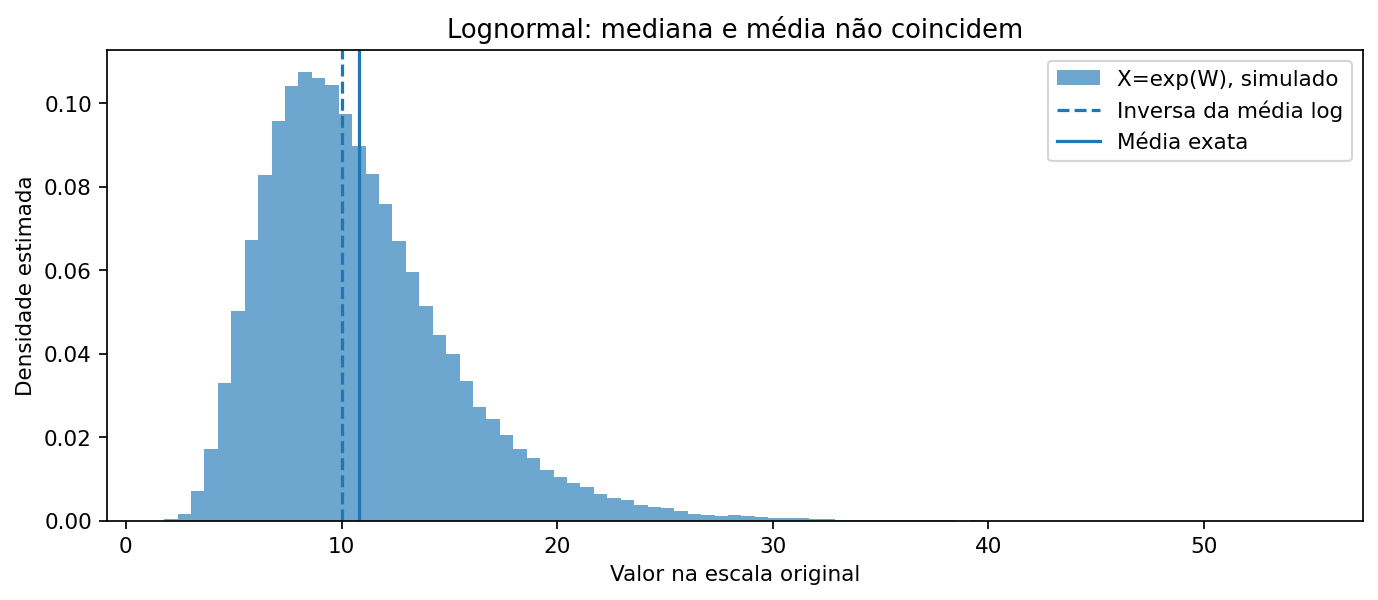

*Figura 4.1 — Histograma de dados lognormais simulados, com a inversa da média logarítmica e a média exata. A assimetria à direita desloca a média para além da mediana.*

O segundo bloco confirma o exemplo **exato** de $\lambda=1/2$ sem gerar valores fora do domínio:

In [ ]:
from scipy.special import inv_boxcox

w = np.array([-1.0, 1.0])
x = inv_boxcox(w, 0.5)
media_w = np.mean(w)
var_w = np.mean((w - media_w)**2)
previsao_ingenua = inv_boxcox(media_w, 0.5)
media_correta = previsao_ingenua + var_w/4

print("Valores originais:", x)             # [0.25, 2.25]
print("Inversa da média:", previsao_ingenua)  # 1.0
print("Média verdadeira:", np.mean(x))       # 1.25
assert np.isclose(media_correta, np.mean(x))

`scipy.special.inv_boxcox` aplica a inversa para um parâmetro fornecido, mas **não calcula automaticamente o viés de retransformação**. O código compara uma média de dois valores com sua expressão analítica; não estima um modelo temporal.

### 8. Intervalos e quantis na escala original

Se $h_\lambda$ é estritamente crescente, quantis são preservados sob transformação monótona: se $q_a(W)$ é um quantil de probabilidade $a$ e $h_\lambda$ é definida nesse valor,

$$
\boxed{q_a(X)=h_\lambda(q_a(W)).}
$$

Assim, quando um modelo fornece quantis preditivos válidos na escala transformada, podemos aplicar a inversa aos **extremos do intervalo preditivo**. Não precisamos aplicar uma correção de Jensen aos quantis, porque não estamos tomando esperanças. A cobertura do intervalo depende da adequação do modelo preditivo e do tratamento correto da incerteza dos parâmetros; a simples inversão não garante calibração estatística.

No caso lognormal condicional, um intervalo central de aproximadamente 95% é

$$
\left[\exp(\mu_h-1{,}96s_h),\;\exp(\mu_h+1{,}96s_h)\right],
$$

sob a aproximação normal e o quantil utilizado. O intervalo é assimétrico na escala original; não se deve construir sua versão original somando e subtraindo um mesmo valor em torno da média corrigida.

### 9. Protocolo completo sem vazamento temporal

Em cada origem de previsão, (1) separar cronologicamente treinamento e teste; (2) inspecionar positividade e dados ausentes, sem substituir ausências por zeros; (3) selecionar/estimar $\lambda$ **somente no treino** usando um modelo de erro justificado; (4) ajustar o modelo temporal à série transformada de treino; (5) produzir uma distribuição/quantis preditivos ou média/variância transformadas, conforme o alvo; (6) inverter respeitando o suporte e, se o alvo for a média, calcular $E[h_\lambda(W)]$ sob uma distribuição compatível ou uma aproximação declarada; (7) avaliar as previsões na escala e com a função de perda que interessam ao problema.

**Diferença entre alvos:** no conjunto de treino, uma transformação pode aproximar erros gaussianos; isso não garante que a média condicional na escala original seja bem calibrada. Compare modelos com critérios relevantes à pergunta científica e documente as decisões tomadas antes de observar os valores de teste.

### 10. Exercícios para autonomia

1. **Interpretação:** explique a diferença entre $h_\lambda(E[W])$, $E[h_\lambda(W)]$ e $h_\lambda(\mathrm{Med}(W))$.
2. **Prova:** derive as duas primeiras derivadas de $h_\lambda$ e classifique sua convexidade para $\lambda=0,1/2,1,2$.
3. **Cálculo:** no modelo lognormal, use $\mu=\log 20$ e $s=0{,}3$ para obter mediana e média; compare a diferença percentual.
4. **Demonstração:** para $\lambda=1/2$, derive a média exata da inversa em função de $E[W]$ e $\mathrm{Var}(W)$.
5. **Python guiado:** faça um pseudocódigo que estime $E[X]$ por simulação de uma distribuição preditiva válida para $W$. Verifique as restrições de suporte antes de programar.
6. **Crítica:** por que uma previsão normal na escala Box–Cox pode ser inconsistente com o domínio da inversa quando $\lambda\ne0$? Sugira uma abordagem que respeite o domínio.
7. **Pesquisa aplicada:** em precipitação com muitos zeros, discuta por que transformar apenas os valores positivos não resolve, por si só, a previsão da probabilidade de chuva.

**Respostas selecionadas:** no exercício 3, a média é $20e^{0{,}045}\approx20{,}9206$, frente à mediana 20. No exercício 4, a correção exata é um quarto da variância transformada. As demais respostas requerem justificativas detalhadas.

### 11. Síntese e fontes

A inversão Box–Cox recupera observações positivas, mas não converte automaticamente uma **média transformada** em uma **média na escala original**. Jensen descreve a direção do desvio sob condições de curvatura; o caso lognormal fornece correção exata e o método delta fornece uma aproximação de segunda ordem. Para previsões científicas, é indispensável declarar o alvo estatístico, o suporte probabilístico, as hipóteses e a avaliação cronológica.

- **Planejamento consultado:** `PLANO_MODULOS_PRIORITARIOS.md`, Módulo 5; `mapeamento-conteudos-series-temporais.md`, lacuna de correção de viés.
- **Referência geral do projeto:** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de séries temporais: modelos lineares univariados*, v. 1, 3ª ed.; **sem atribuição específica a páginas não examinadas para esta seção**.
- **Complementação didática original:** deduções de Jensen e Taylor aplicadas à inversa, exemplos de lognormal e $\lambda=1/2$, código, figuras e exercícios.

**Continuidade:** no Módulo 6 estudaremos decomposição clássica, modelos aditivos/multiplicativos e posteriormente STL/MSTL, relacionando escala, tendência, sazonalidade e resíduos.